# Global Road Surface Explorative Analysis

This notebook analyzes global road surface classifications across multiple years (2016, 2020, 2024), computing pavedness metrics and tracking changes over time.

## 1. Configuration

In [3]:
from pathlib import Path
import os

import shapely

BASE_DATA_DIR = Path("Path/To/Road_Surface_Paper_Data_Planet")
DATASETS_DIR = Path("Path/To/Datasets")


URBAN_CENTERS_GPKG = DATASETS_DIR / "urban_centers_db" / "GHS_UCDB_GLOBE_R2024A.gpkg"

WORLD_SHAPEFILE = DATASETS_DIR / "ne_110m_admin_0_countries" / "ne_110m_admin_0_countries.shp"

ROAD_SURFACES_BASE = BASE_DATA_DIR / "road_surfaces"
PARQUET_PATHS = {
    2024: ROAD_SURFACES_BASE / "2024" / "results" / "final" / "analytics" / "all_roads_final.parquet",
    2020: ROAD_SURFACES_BASE / "2020" / "results" / "final" / "analytics" / "all_roads_final.parquet",
    2016: ROAD_SURFACES_BASE / "2016" / "results" / "final" / "analytics" / "all_roads_final.parquet"
}

# Risk data
RISK_PARQUET = DATASETS_DIR / "all_roads_final_with_risk.parquet"

OUTPUT_DIR = Path("Path/to/Road_Surface_Paper_Data_Planet/plots")
INTERMEDIATE_DIR = OUTPUT_DIR / "intermediate_duckdb"
PLOTS_DIR = OUTPUT_DIR / "plots"
MAPS_DIR = OUTPUT_DIR / "maps"
MERGED_COUNTRIES_DIR = ROAD_SURFACES_BASE / "merged_countries"


GRID_GEOJSON = OUTPUT_DIR / "final_grid_urban_rural_with_explicit_total.geojson"
PAVEDNESS_GPKG = MAPS_DIR / "pavedness.gpkg"
UNKNOWN_SHARE_GPKG = MAPS_DIR / "unknown_share.gpkg"


GRID_STEP_DEGREES = 2  # Grid cell size in degrees
H3_RESOLUTION = 3      # H3 hexagonal grid resolution
CRS_WGS84 = 4326
CRS_MOLLWEIDE = "ESRI:54009"


for directory in [OUTPUT_DIR, INTERMEDIATE_DIR, PLOTS_DIR, MAPS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Print configuration summary
print("Configuration loaded successfully!")
print(f"  Base data directory: {BASE_DATA_DIR}")
print(f"  Output directory: {OUTPUT_DIR}")
print(f"  Parquet files: {list(PARQUET_PATHS.keys())}")

# --- Nature Reviews Journals figure specifications ---
# Source: https://www.nature.com/documents/NRJs-guide-to-preparing-final-artwork.pdf
_MM_PER_INCH = 25.4

# Column widths in mm (research/review content)
NRJ_1COL_WIDTH_MM = 88
NRJ_2COL_WIDTH_MM = 180

# Column widths in inches (for matplotlib figsize)
NRJ_1COL_WIDTH_IN = NRJ_1COL_WIDTH_MM / _MM_PER_INCH   # ~3.46 in
NRJ_2COL_WIDTH_IN = NRJ_2COL_WIDTH_MM / _MM_PER_INCH   # ~7.09 in

# Maximum figure heights in mm, keyed by max caption word count
# (longer captions leave less vertical space for the figure)
NRJ_MAX_HEIGHT_1COL_MM = {300: 130, 150: 180, 50: 220}
NRJ_MAX_HEIGHT_2COL_MM = {300: 185, 150: 210, 50: 225}

# Same heights in inches
NRJ_MAX_HEIGHT_1COL_IN = {k: v / _MM_PER_INCH for k, v in NRJ_MAX_HEIGHT_1COL_MM.items()}
NRJ_MAX_HEIGHT_2COL_IN = {k: v / _MM_PER_INCH for k, v in NRJ_MAX_HEIGHT_2COL_MM.items()}

# Typography — sans-serif required; Helvetica or Arial preferred
NRJ_FONT_FAMILY = "Liberation Sans"  # Arial substitute available on this system
NRJ_FONT_SIZE_MAX_PT = 6   # maximum label/tick text size (NRJ allows up to 7)
NRJ_FONT_SIZE_MIN_PT = 5   # minimum label/tick text size

# Export
NRJ_DPI = 800              # minimum resolution for bitmap/combination figures
NRJ_COLOR_MODE = "RGB"     # research and review articles use RGB

Configuration loaded successfully!
  Base data directory: /home/clemens/mnt/sds-hd/sd17f001/Road_Surface_Paper_Data_Planet
  Output directory: /home/clemens/mnt/sds-hd/sd17f001/Road_Surface_Paper_Data_Planet/plots
  Parquet files: [2024, 2020, 2016]


## 2. Imports

In [4]:
import numpy as np
import pandas as pd
import geopandas as gpd
import duckdb
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from shapely.geometry import box
from shapely import from_wkt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

## 3. Data Preparation

### 3.1 Load Urban Centers

In [ ]:
gdf_urban_centers = gpd.read_file(str(URBAN_CENTERS_GPKG)).to_crs(CRS_WGS84)
print(f"Loaded {len(gdf_urban_centers):,} urban centers")

gdf_urban_centers["geometry_wkt"] = gdf_urban_centers["geometry"].apply(
    lambda g: g.wkt if g else None
)
gdf_urban_centers.drop(columns=["geometry"], inplace=True)

con = duckdb.connect()
con.execute("INSTALL spatial; LOAD spatial;")
con.execute("DROP TABLE IF EXISTS urban_centers;")
con.execute("""
    CREATE TABLE urban_centers AS
    SELECT ID_UC_G0, ST_GeomFromText(geometry_wkt) AS geom
    FROM gdf_urban_centers
""")

### 3.2 Create Spatial Grid

In [ ]:
xs = np.arange(-180, 180, GRID_STEP_DEGREES)
ys = np.arange(-90, 90, GRID_STEP_DEGREES)
grid_cells = [box(x, y, x + GRID_STEP_DEGREES, y + GRID_STEP_DEGREES).wkt 
              for x in xs for y in ys]

gdf_grid = pd.DataFrame({"grid_id": range(len(grid_cells)), "geometry_wkt": grid_cells})
print(f"Created {len(gdf_grid):,} grid cells")

con.execute("DROP TABLE IF EXISTS grid;")
con.execute("""
    CREATE TABLE grid AS
    SELECT grid_id, ST_GeomFromText(geometry_wkt) AS geom FROM gdf_grid
""")
con.execute("""
    CREATE INDEX idx_grid ON grid USING RTREE (geom);
    CREATE INDEX idx_urban ON urban_centers USING RTREE (geom);
""")

### 3.3 Load and Join Multi-Year Road Data

In [ ]:
print("Loading 2024 data...")
con.execute(f"""
    CREATE OR REPLACE TABLE base_2024 AS
    SELECT osm_id, road_class AS road_class_2024, length AS length_2024,
           country, continent, osm_tags_highway,
           ST_AsWKB(ST_Centroid(geometry)) AS centroid_wkb
    FROM read_parquet('{PARQUET_PATHS[2024]}')
""")
con.execute(f"COPY base_2024 TO '{INTERMEDIATE_DIR / 'base_2024.parquet'}' (FORMAT PARQUET)")

print("Loading 2020 data...")
con.execute(f"""
    CREATE OR REPLACE TABLE road_2020 AS
    SELECT osm_id, road_class AS road_class_2020, length AS length_2020
    FROM read_parquet('{PARQUET_PATHS[2020]}')
""")
con.execute(f"COPY road_2020 TO '{INTERMEDIATE_DIR / 'road_2020.parquet'}' (FORMAT PARQUET)")

print("Loading 2016 data...")
con.execute(f"""
    CREATE OR REPLACE TABLE road_2016 AS
    SELECT osm_id, road_class AS road_class_2016, length AS length_2016
    FROM read_parquet('{PARQUET_PATHS[2016]}')
""")
con.execute(f"COPY road_2016 TO '{INTERMEDIATE_DIR / 'road_2016.parquet'}' (FORMAT PARQUET)")

print("Classifying urban/rural...")
con.execute(f"""
    CREATE OR REPLACE TABLE urban_classified AS
    SELECT b.*,
           CASE WHEN EXISTS (
               SELECT 1 FROM urban_centers uc
               WHERE ST_Intersects(ST_GeomFromWKB(b.centroid_wkb), uc.geom)
           ) THEN 'urban' ELSE 'rural' END AS urban_rural
    FROM read_parquet('{INTERMEDIATE_DIR / 'base_2024.parquet'}') b
""")
con.execute(f"COPY urban_classified TO '{INTERMEDIATE_DIR / 'urban_classified.parquet'}' (FORMAT PARQUET)")

# Sanity check
check = con.execute(f"""
    SELECT COUNT(*) AS total,
           COUNT(centroid_wkb) AS non_null_centroid,
           COUNT(CASE WHEN urban_rural = 'urban' THEN 1 END) AS urban_count,
           COUNT(CASE WHEN urban_rural = 'rural' THEN 1 END) AS rural_count
    FROM read_parquet('{INTERMEDIATE_DIR / 'urban_classified.parquet'}')
""").df()
print(check)

print("Joining with grid...")
con.execute(f"""
    CREATE OR REPLACE TABLE joined AS
    SELECT g.grid_id, g.geom AS grid_geom, u.osm_id, u.country, u.continent,
           u.osm_tags_highway, u.road_class_2024, u.length_2024,
           r20.road_class_2020, r20.length_2020, r16.road_class_2016, r16.length_2016,
           u.urban_rural
    FROM read_parquet('{INTERMEDIATE_DIR / 'urban_classified.parquet'}') u
    LEFT JOIN read_parquet('{INTERMEDIATE_DIR / 'road_2020.parquet'}') r20 USING (osm_id)
    LEFT JOIN read_parquet('{INTERMEDIATE_DIR / 'road_2016.parquet'}') r16 USING (osm_id)
    JOIN grid g ON ST_Intersects(ST_GeomFromWKB(u.centroid_wkb), g.geom)
""")
con.execute(f"COPY joined TO '{INTERMEDIATE_DIR / 'joined.parquet'}' (FORMAT PARQUET)")

print("Data preparation complete")

### 3.4 Aggregate and Export

In [ ]:
con = duckdb.connect()
con.execute("INSTALL SPATIAL; LOAD SPATIAL")

query = f"""
WITH base AS (
    SELECT osm_id, grid_id, grid_geom, country, continent, osm_tags_highway,
           CAST(urban_rural AS VARCHAR) AS urban_rural,
           road_class_2016, road_class_2020, road_class_2024,
           length_2016, length_2020, length_2024
    FROM read_parquet('{INTERMEDIATE_DIR / 'joined.parquet'}')
),
with_total AS (
    SELECT * FROM base
    UNION ALL
    SELECT osm_id, grid_id, grid_geom, country, continent, osm_tags_highway,
           'total' AS urban_rural,
           road_class_2016, road_class_2020, road_class_2024,
           length_2016, length_2020, length_2024
    FROM base
)
SELECT grid_id, ST_AsText(grid_geom) AS geometry, country, continent,
       osm_tags_highway, urban_rural, road_class_2016, road_class_2020, road_class_2024,
       SUM(COALESCE(length_2016, 0)) AS length_2016,
       SUM(COALESCE(length_2020, 0)) AS length_2020,
       SUM(COALESCE(length_2024, 0)) AS length_2024
FROM with_total
GROUP BY ALL
ORDER BY grid_id, urban_rural, country
"""

df = con.execute(query).fetch_df()
df["geom"] = df["geometry"].apply(from_wkt)
gdf = gpd.GeoDataFrame(df, geometry="geom", crs=f"EPSG:{CRS_WGS84}")

gdf.to_file(str(GRID_GEOJSON), driver="GeoJSON")
print(f"Saved {len(gdf):,} records to {GRID_GEOJSON}")
con.close()

## 4. Analysis

### 4.1 Load Data and Setup

In [10]:
import pycountry
import requests
import pandas as pd
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import warnings

if not GRID_GEOJSON.exists():
    GRID_GEOJSON = DATASETS_DIR / "final_grid_urban_rural_with_explicit_total.geojson"

if not GRID_GEOJSON.exists():
    raise FileNotFoundError(f"Grid GeoJSON not found at {GRID_GEOJSON} Please ensure to either run the pipeline or download the file from the link provided in the README.")
gdf = gpd.read_file(str(GRID_GEOJSON))
print(f"Loaded {len(gdf):,} records")

world = gpd.read_file(str(WORLD_SHAPEFILE))
world = world[world["NAME"] != "Antarctica"]
world_dissolved = world.dissolve().geometry.iloc[0]

def add_world_and_cartopy_gridlines(ax, world_gdf):
    """Add dissolved world outline and gridlines to a Cartopy axis."""
    # Set extent to crop below 65°S
    ax.set_extent([-182, 182, -65, 80], crs=ccrs.PlateCarree())

    # Shadow effect
    shadow = [PathEffects.withSimplePatchShadow(offset=(1.5, -1.5),
                                                shadow_rgbFace='black', alpha=0.35)]
    # Gridlines
    gl = ax.gridlines(draw_labels=False, linewidth=0.5,
                      linestyle='--', color='gray', alpha=0.5)
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER

    # Plot shadow and world (single geometry)
    world_gdf.plot(ax=ax, transform=ccrs.PlateCarree(),
                   facecolor='lightgrey', edgecolor='lightgrey',
                   linewidth=0.5, path_effects=shadow,zorder=2)


Loaded 463,493 records


In [11]:
warnings.filterwarnings("ignore")

df_shdi = pd.read_csv(DATASETS_DIR / 'SHDI-SGDI-Total 8.0.csv')

#get wb data
url = "http://api.worldbank.org/v2/country?per_page=300&format=json"
resp = requests.get(url)
data = resp.json()[1]

df_wb = pd.DataFrame([{
    "iso_alpha3": c["id"],
    "country_name": c["name"],
    "wb_region": c["region"]["value"]
} for c in data])

df_wb = df_wb[df_wb["wb_region"] != "Aggregates"].reset_index(drop=True)


def alpha2_to_alpha3(alpha2_code):
        try:
            country = pycountry.countries.get(alpha_2=alpha2_code.upper())
            return country.alpha_3 if country else None
        except:
            return None

gdf['iso_A3'] = gdf['country'].apply(lambda x: alpha2_to_alpha3(x))

gdf_countries = gdf.groupby(['iso_A3',"urban_rural","road_class_2016","road_class_2020","road_class_2024"]).agg({
    'length_2016': 'sum',
    'length_2020': 'sum',
    'length_2024': 'sum'
}).reset_index()

gdf_countries = gdf_countries.merge(
    df_wb,
    left_on='iso_A3',
    right_on='iso_alpha3',
    how='left')


data = []
df_adb = df_shdi
indicators=[
 'sgdi',
 'shdi',
 'shdif',
 'shdim',
 'healthindex',
 'healthindexf',
 'healthindexm',
 'incindex',
 'incindexf',
 'incindexm',
 'edindex',
 'edindexf',
 'edindexm',
 'esch',
 'eschf',
 'eschm',
 'msch',
 'mschf',
 'mschm',
 'lifexp',
 'lifexpf',
 'lifexpm',
 'gnic',
 'gnicf',
 'gnicm',
 'lgnic',
 'lgnicf',
 'lgnicm',
 'pop']

info_columns = [col for col in df_adb.columns if col not in indicators]


for country in df_adb.country.unique():
    data_point = {col: df_adb[df_adb.country == country][col].values[0] for col in info_columns  if col != "year"}
    df_country = df_adb[df_adb.country == country]
    for indicator in indicators:
        # drop nan values in the column of th the according indicator
        df_country[indicator] = pd.to_numeric(df_country[indicator], errors='coerce')
        df_indicator = df_country.dropna(subset=[indicator])

        years = list(df_indicator.year.unique())
        years.sort(reverse=True)  # sort years descending
        if len(years) == 0:
            continue  # skip if no valid years
        year = years[0]
        value = df_indicator[df_indicator.year == year][indicator].values[0]
        data_point[indicator] = value
        data_point[f"year_{indicator}"] = year
    data.append(data_point)
df_shdi = pd.DataFrame(data)

#merge only the columns  shdi and sgdi onto the gdf_countries dataframe
gdf_countries = gdf_countries.merge(
    df_shdi[['iso_code', 'shdi', 'sgdi']],
    left_on='iso_A3',
    right_on='iso_code',
    how='left'
)

### 4.2 Pavedness Analysis

Pavedness = paved length / (paved + unpaved length)

In [12]:
def compute_pavedness(gdf, region_type="total"):
    gdf_work = gdf.to_crs(CRS_MOLLWEIDE).copy()
    
    def aggregate_year(year):
        rc, ln = f"road_class_{year}", f"length_{year}"
        df = gdf_work[(gdf_work[rc].isin(["paved", "unpaved"])) & 
                      (gdf_work["urban_rural"] == region_type)]
        grouped = df.groupby(["grid_id", "geometry", rc])[ln].sum().reset_index()
        grouped = gpd.GeoDataFrame(grouped, geometry="geometry", crs=gdf_work.crs)
        
        paved = grouped[grouped[rc] == "paved"].copy()
        unpaved = grouped[grouped[rc] == "unpaved"].copy()
        merged = paved.merge(unpaved, on=["grid_id", "geometry"], suffixes=("_paved", "_unpaved"))
        merged["pavedness"] = 100 * merged[f"{ln}_paved"] / (merged[f"{ln}_paved"] + merged[f"{ln}_unpaved"])
        return merged
    
    gdf_2020 = aggregate_year(2020)
    gdf_2024 = aggregate_year(2024)
    
    change = gdf_2024.merge(gdf_2020, on=["grid_id", "geometry"], suffixes=("_2024", "_2020"))
    change["change"] = change["pavedness_2024"] - change["pavedness_2020"]
    change = gpd.GeoDataFrame(change, geometry="geometry", crs=gdf_work.crs)
    
    return {"2020": gdf_2020, "2024": gdf_2024, "change": change}



for rt in ["total", "urban", "rural"]:
    print(f"Processing {rt}...")
    results = compute_pavedness(gdf, rt)
    results["2020"].to_crs(CRS_WGS84).to_file(str(PAVEDNESS_GPKG), layer=f"pavedness_2020_{rt}", driver="GPKG")
    results["2024"].to_crs(CRS_WGS84).to_file(str(PAVEDNESS_GPKG), layer=f"pavedness_2024_{rt}", driver="GPKG")
    results["change"].to_crs(CRS_WGS84).to_file(str(PAVEDNESS_GPKG), layer=f"change_{rt}", driver="GPKG")

Processing total...
Processing urban...
Processing rural...


In [13]:
def compute_unknown_share(gdf, region_type="total"):
    gdf_work = gdf.to_crs(CRS_MOLLWEIDE).copy()

    def aggregate_year(year):
        rc, ln = f"road_class_{year}", f"length_{year}"
        df = gdf_work[(gdf_work[rc].isin(["paved", "unpaved", "unknown"])) &
                      (gdf_work["urban_rural"] == region_type)]
        grouped = df.groupby(["grid_id", "geometry", rc])[ln].sum().reset_index()
        grouped = gpd.GeoDataFrame(grouped, geometry="geometry", crs=gdf_work.crs)

        paved = grouped[grouped[rc] == "paved"].rename(columns={ln: "length_paved"})
        unpaved = grouped[grouped[rc] == "unpaved"].rename(columns={ln: "length_unpaved"})
        unknown = grouped[grouped[rc] == "unknown"].rename(columns={ln: "length_unknown"})

        merged = (paved.merge(unpaved, on=["grid_id", "geometry"], how="outer")
                       .merge(unknown, on=["grid_id", "geometry"], how="outer"))
        for col in ["length_paved", "length_unpaved", "length_unknown"]:
            merged[col] = merged[col].fillna(0)

        denom = merged["length_paved"] + merged["length_unpaved"] + merged["length_unknown"]
        merged["unknown_share"] = np.where(denom > 0, 100 * merged["length_unknown"] / denom, 0.0)
        return gpd.GeoDataFrame(merged, geometry="geometry", crs=gdf_work.crs)

    gdf_2020 = aggregate_year(2020)
    gdf_2024 = aggregate_year(2024)

    change = gdf_2024.merge(gdf_2020, on=["grid_id", "geometry"], suffixes=("_2024", "_2020"))
    change["change"] = change["unknown_share_2024"] - change["unknown_share_2020"]
    change = gpd.GeoDataFrame(change, geometry="geometry", crs=gdf_work.crs)

    return {"2020": gdf_2020, "2024": gdf_2024, "change": change}


UNKNOWN_GPKG = OUTPUT_DIR / "unknown_share.gpkg"
if UNKNOWN_GPKG.exists():
    UNKNOWN_GPKG.unlink()

for rt in ["total", "urban", "rural"]:
    print(f"Processing {rt}...")
    results = compute_unknown_share(gdf, rt)
    results["2020"].to_crs(CRS_WGS84).to_file(str(UNKNOWN_GPKG), layer=f"unknown_share_2020_{rt}", driver="GPKG")
    results["2024"].to_crs(CRS_WGS84).to_file(str(UNKNOWN_GPKG), layer=f"unknown_share_2024_{rt}", driver="GPKG")
    results["change"].to_crs(CRS_WGS84).to_file(str(UNKNOWN_GPKG), layer=f"unknown_share_change_{rt}", driver="GPKG")

Processing total...
Processing urban...
Processing rural...


### 4.3 latex tables

In [14]:
import pandas as pd
import numpy as np


def compute_pavedness_tables_wide(gdf_countries, df_wb, year=2024):
    road_col = f"road_class_{year}"
    length_col = f"length_{year}"

    # Filter only paved/unpaved roads
    gdf = gdf_countries[gdf_countries[road_col].isin(["paved", "unpaved"])].copy()

    # Sum by country, area type, and road type
    gdf = gdf.groupby(["iso_A3", "urban_rural", road_col])[length_col].sum().reset_index()

    # Separate paved/unpaved
    paved = gdf[gdf[road_col] == "paved"].rename(columns={length_col: "length_paved"})
    unpaved = gdf[gdf[road_col] == "unpaved"].rename(columns={length_col: "length_unpaved"})

    # Combine and compute pavedness %
    gdf_combined = paved.merge(unpaved, on=["iso_A3", "urban_rural"], how="outer")
    gdf_combined["pavedness"] = 100 * gdf_combined["length_paved"] / (
        gdf_combined["length_paved"] + gdf_combined["length_unpaved"]
    )

    # Also compute "total" pavedness (ignore rural/urban split)
    total_group = gdf.groupby(["iso_A3", road_col])[length_col].sum().reset_index()
    total_paved = total_group[total_group[road_col] == "paved"].rename(columns={length_col: "length_paved"})
    total_unpaved = total_group[total_group[road_col] == "unpaved"].rename(columns={length_col: "length_unpaved"})
    total_combined = total_paved.merge(total_unpaved, on="iso_A3", how="outer")
    total_combined["pavedness"] = 100 * total_combined["length_paved"] / (
        total_combined["length_paved"] + total_combined["length_unpaved"]
    )
    total_combined["urban_rural"] = "total"  # mark as total

    # Combine total + rural/urban
    gdf_all = pd.concat([gdf_combined, total_combined], ignore_index=True)

    # Pivot to wide format
    wide = gdf_all.pivot_table(
        index="iso_A3",
        columns="urban_rural",
        values="pavedness"
    ).reset_index()

    # Rename columns
    wide.columns.name = None
    wide = wide.rename(columns={
        "total": "total_pavedness",
        "urban": "urban_pavedness",
        "rural": "rural_pavedness"
    })

    # Merge WB region info
    wide = wide.merge(df_wb[["iso_alpha3", "wb_region"]], left_on="iso_A3", right_on="iso_alpha3", how="left")

    # Sort by total pavedness
    wide = wide.sort_values(by="total_pavedness", ascending=True)

    return wide


def _wide_to_long(wide_df):
    """
    Convert the wide-format output of compute_pavedness_tables_wide
    back to long format with columns: iso_A3, wb_region, urban_rural, pavedness.
    """
    pav_cols = {
        "total_pavedness": "total",
        "urban_pavedness": "urban",
        "rural_pavedness": "rural",
    }
    # Only melt columns that exist
    existing = {k: v for k, v in pav_cols.items() if k in wide_df.columns}
    if not existing:
        raise ValueError("Wide DataFrame has no recognised pavedness columns "
                         "(expected total_pavedness, urban_pavedness, rural_pavedness)")

    long = wide_df.melt(
        id_vars=["iso_A3", "wb_region"],
        value_vars=list(existing.keys()),
        var_name="urban_rural",
        value_name="pavedness",
    )
    long["urban_rural"] = long["urban_rural"].map(existing)
    return long


def _build_region_table(long_df):
    grp = long_df.groupby(["wb_region", "urban_rural"])["pavedness"]
    reg = grp.agg(["mean", "std", "count"]).reset_index()
    reg.columns = ["wb_region", "urban_rural", "mean_pavedness", "std_pavedness", "country_count"]
    return reg


def make_wide_and_latex_compact_sorted(
    continent_table,
    country_table,
    decimals: int = 1,
    top_n: int = 10,
    bottom_n: int = 10,
):
    def _is_wide(df):
        return "total_pavedness" in df.columns or "urban_pavedness" in df.columns

    if _is_wide(country_table):
        long_country = _wide_to_long(country_table)
        # Build a per-country "table" with mean/std (std = NaN for single obs)
        country_long = long_country.copy()
        country_long["mean_pavedness"] = country_long["pavedness"]
        country_long["std_pavedness"] = np.nan  # single observation per country
        country_long = country_long[["iso_A3", "wb_region", "urban_rural",
                                     "mean_pavedness", "std_pavedness"]]
    else:
        country_long = country_table.copy()

    if _is_wide(continent_table):
        # continent_table was accidentally passed as wide too
        long_cont = _wide_to_long(continent_table)
        continent_long = _build_region_table(long_cont)
    elif {"wb_region", "urban_rural", "mean_pavedness"}.issubset(continent_table.columns):
        continent_long = continent_table.copy()
    else:
        # Derive region table from country data
        long_for_reg = _wide_to_long(country_table) if _is_wide(country_table) else None
        if long_for_reg is not None:
            continent_long = _build_region_table(long_for_reg)
        else:
            raise ValueError("Cannot determine region-level statistics from inputs.")

    def fmt(mean, sd):
        if pd.isna(mean):
            return "--"
        if pd.isna(sd):
            return f"{mean:.{decimals}f}"
        return f"{mean:.{decimals}f} \u00b1 {sd:.{decimals}f}"

    reg = continent_long.copy()
    reg_fmt = reg.pivot(index="wb_region",
                        columns="urban_rural",
                        values=["mean_pavedness", "std_pavedness"])

    # Key for sorting: total mean if present, else across areas
    if ("mean_pavedness", "total") in reg_fmt.columns:
        total_key = reg_fmt[("mean_pavedness", "total")].copy()
    else:
        total_key = reg_fmt["mean_pavedness"].mean(axis=1)

    # Drop NaN rows
    valid_idx = total_key.dropna().index
    reg_fmt = reg_fmt.loc[valid_idx]
    total_key = total_key.loc[valid_idx]
    reg = reg[reg["wb_region"].isin(valid_idx)]

    # Build formatted output (skip "total" -- used for sorting only)
    reg_out = pd.DataFrame(index=reg_fmt.index)
    for area in reg["urban_rural"].dropna().unique():
        if area == "total":
            continue  # total used for sorting, not displayed
        mean = reg_fmt["mean_pavedness"].get(area)
        sd = reg_fmt["std_pavedness"].get(area)
        if mean is not None and sd is not None:
            reg_out[area.title()] = [fmt(m, s) for m, s in zip(mean, sd)]

    cc = reg.groupby("wb_region")["country_count"].max()
    reg_out["N countries"] = cc

    # Sort by total_key
    reg_out = reg_out.loc[total_key.sort_values(ascending=False).index]
    reg_out.index.name = "Region"

    latex_regions = reg_out.to_latex(
        index=True,
        escape=False,
        caption=(r"\textbf{Pavedness by World Bank Region and Area Type (sorted by Total).} "
                 r"Values are mean $\pm$ SD (\%)."),
        label="tab:wb_regions_pavedness_sorted",
    )

    ctab = country_long.copy()
    mean_w = ctab.pivot(index="iso_A3", columns="urban_rural", values="mean_pavedness")
    sd_w = ctab.pivot(index="iso_A3", columns="urban_rural", values="std_pavedness")

    if "total" in mean_w.columns:
        overall_mean = mean_w["total"]
        overall_sd = sd_w["total"]
    else:
        overall_mean = mean_w.mean(axis=1)
        overall_sd = sd_w.mean(axis=1)

    valid_idx = overall_mean.dropna().index
    overall_mean = overall_mean.loc[valid_idx]
    overall_sd = overall_sd.loc[valid_idx]
    mean_w = mean_w.loc[valid_idx]
    sd_w = sd_w.loc[valid_idx]

    # Ranking
    order = overall_mean.sort_values(ascending=False)
    positions = pd.Series(range(1, len(order) + 1), index=order.index, name="Position")

    # Build formatted output
    country_out = pd.DataFrame(index=overall_mean.index)
    country_out["Overall"] = [fmt(m, s) for m, s in zip(overall_mean, overall_sd)]

    # Add per-area cols (skip "total" -- already captured by "Overall")
    pref_order = [c for c in ["urban", "rural"] if c in mean_w.columns]
    other_areas = [c for c in mean_w.columns if c not in pref_order and c != "total"]
    ordered_areas = pref_order + sorted(other_areas)

    for col in ordered_areas:
        country_out[col.title()] = [fmt(m, s) for m, s in zip(mean_w[col], sd_w[col])]

    # Attach positions and sort
    country_out = country_out.join(positions).loc[order.index]
    country_out.index.name = "Country (ISO3)"

    cols = ["Position"] + [c for c in country_out.columns if c != "Position"]

    top_idx = order.head(top_n).index
    bot_idx = order.tail(bottom_n).index

    top_block = country_out.loc[top_idx][cols].copy()
    bot_block = country_out.loc[bot_idx][cols].copy().sort_values("Position")

    ellipsis_row = {c: r"\dots" for c in cols}
    ellipsis_df = pd.DataFrame([ellipsis_row], index=[r"\dots"])

    topbottom_df = pd.concat([top_block, ellipsis_df, bot_block], axis=0)

    latex_topbot = topbottom_df.to_latex(
        index=True,
        escape=False,
        caption=(r"\textbf{Countries ranked by Overall/Total pavedness (mean $\pm$ SD, \%).} "
                 r"Only valid values are shown. Highest and lowest subsets displayed with ellipsis."),
        label="tab:countries_pavedness_positions",
    )

    full_df = country_out.loc[order.index][cols].copy()

    latex_full = full_df.to_latex(
        index=True,
        escape=False,
        longtable=True,
        caption=(r"\textbf{All countries ranked by Overall/Total pavedness (mean $\pm$ SD, \%).}"),
        label="tab:countries_pavedness_full",
    )

    return reg_out, latex_regions, topbottom_df, latex_topbot, full_df, latex_full


# Compute wide-format pavedness table from raw data
country_table = compute_pavedness_tables_wide(gdf_countries, df_wb, year=2024)

# Pass as both continent and country table — region stats are derived internally
reg_out, latex_regions, topbottom_df, latex_topbot, full_df, latex_full = make_wide_and_latex_compact_sorted(
    country_table, country_table, decimals=1, top_n=10, bottom_n=10
)

In [15]:
full_df

,Position,Overall,Urban,Rural
iso_A3,,,,
QAT,1,100.0,--,100.0
BRB,2,100.0,--,100.0
KWT,3,100.0,99.9,100.0
ARE,4,100.0,100.0,99.9
IRL,5,99.9,99.9,99.9
...,...,...,...,...
GIN,204,35.1,92.9,32.0
BDI,205,31.3,95.2,29.5
SSD,206,25.3,73.2,24.5


### 4.4 Correlation plot

In [25]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import pandas as pd
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.metrics import r2_score, roc_auc_score
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

def simple_nice_round(x):
    if x == 0:
        return 0
    exponent = np.floor(np.log10(x))
    return np.ceil(x / 10**exponent) * 10**exponent

def fmt_km(l):
    if l == 0:
        return "0 km"
    elif l >= 1e6:
        return f"{l/1e6:.1f}M km"
    elif l >= 1e3:
        return f"{l/1e3:.0f}k km"
    return f"{l:.0f} km"

def _partial_corr(x, y, controls_df: pd.DataFrame):
    if controls_df is None or controls_df.shape[1] == 0:
        return pearsonr(x, y)
    Z = np.c_[np.ones(len(controls_df)), controls_df.values]
    bx = np.linalg.lstsq(Z, x, rcond=None)[0]
    by = np.linalg.lstsq(Z, y, rcond=None)[0]
    rx = x - Z @ bx
    ry = y - Z @ by
    return pearsonr(rx, ry)


# -----------------------------------------------------------------------------
# World Bank region colours
# -----------------------------------------------------------------------------
# Choose one of: "wong_standard", "tol_light", "tol_muted", "okabe_ito", "tol_bright", "tol_vibrant".
# "wong_standard" uses the standard Wong / Okabe-Ito colour order.
WB_REGION_PALETTE = "wong_standard"

WB_REGION_PALETTE_OPTIONS = {
    # Polished, softer Paul Tol palette; still designed for colour-blind-safe use.
    "tol_light": {
        "East Asia & Pacific": "#77AADD",          # light blue
        "Europe & Central Asia": "#4477AA",        # blue
        "Latin America & Caribbean": "#AA4488",    # mauve
        "Middle East & North Africa": "#DDCC77",   # sand
        "North America": "#CC6677",                # rose
        "South Asia": "#228833",                   # green
        "Sub-Saharan Africa": "#44AA99",           # teal
    },
    # Standard Wong / Okabe-Ito colour order.
    "wong_standard": {
        "East Asia & Pacific": "#000000",          # black
        "Europe & Central Asia": "#E69F00",        # orange
        "Latin America & Caribbean": "#56B4E9",    # sky blue
        "Middle East & North Africa": "#009E73",   # bluish green
        "North America": "#F0E442",                # yellow
        "South Asia": "#0072B2",                   # blue
        "Sub-Saharan Africa": "#D55E00",           # vermillion
    },
    # Softest option; good default for dense journal figures.
    "tol_muted": {
        "East Asia & Pacific": "#88CCEE",          # cyan
        "Europe & Central Asia": "#332288",        # indigo
        "Latin America & Caribbean": "#AA4499",    # purple
        "Middle East & North Africa": "#DDCC77",   # sand
        "North America": "#882255",                # wine
        "South Asia": "#CC6677",                   # rose
        "Sub-Saharan Africa": "#44AA99",           # teal
    },
    # High-recognition colour-blind-safe palette from Okabe-Ito / Wong.
    "okabe_ito": {
        "East Asia & Pacific": "#56B4E9",          # sky blue
        "Europe & Central Asia": "#0072B2",        # blue
        "Latin America & Caribbean": "#CC79A7",    # reddish purple
        "Middle East & North Africa": "#E69F00",   # orange
        "North America": "#000000",                # black
        "South Asia": "#D55E00",                   # vermillion
        "Sub-Saharan Africa": "#009E73",           # bluish green
    },
    # More saturated than tol_muted while remaining distinct.
    "tol_bright": {
        "East Asia & Pacific": "#66CCEE",          # cyan
        "Europe & Central Asia": "#4477AA",        # blue
        "Latin America & Caribbean": "#AA3377",    # purple
        "Middle East & North Africa": "#CCBB44",   # yellow
        "North America": "#EE6677",                # red
        "South Asia": "#228833",                   # green
        "Sub-Saharan Africa": "#BBBBBB",           # grey
    },
    # Strong but less primary-looking than bright; useful when printed small.
    "tol_vibrant": {
        "East Asia & Pacific": "#33BBEE",          # cyan
        "Europe & Central Asia": "#0077BB",        # blue
        "Latin America & Caribbean": "#EE3377",    # magenta
        "Middle East & North Africa": "#EE7733",   # orange
        "North America": "#CC3311",                # red
        "South Asia": "#009988",                   # teal
        "Sub-Saharan Africa": "#BBBBBB",           # grey
    },
}

WONG_FALLBACK_PALETTE = [
    "#000000", "#E69F00", "#56B4E9", "#009E73",
    "#F0E442", "#0072B2", "#D55E00", "#CC79A7",
]


def _active_wb_region_colors():
    if WB_REGION_PALETTE not in WB_REGION_PALETTE_OPTIONS:
        available = ", ".join(WB_REGION_PALETTE_OPTIONS)
        raise ValueError(f"Unknown WB_REGION_PALETTE: {WB_REGION_PALETTE!r}. Choose one of: {available}")
    return WB_REGION_PALETTE_OPTIONS[WB_REGION_PALETTE]


def _ordered_wb_regions(regions):
    wb_region_colors = _active_wb_region_colors()
    region_set = set(regions)
    fixed_regions = [region for region in wb_region_colors if region in region_set]
    extra_regions = sorted(region_set - set(wb_region_colors))
    return fixed_regions + extra_regions


def _wb_region_color_map(wb_regions):
    wb_region_colors = _active_wb_region_colors()
    color_map = {
        region: wb_region_colors[region]
        for region in wb_regions
        if region in wb_region_colors
    }
    fallback_colors = [color for color in WONG_FALLBACK_PALETTE if color not in color_map.values()]

    for i, region in enumerate(region for region in wb_regions if region not in color_map):
        color_map[region] = fallback_colors[i % len(fallback_colors)]

    return color_map


def _log_wb_region_colors(region_color_map):
    print(f"WB region palette used: {WB_REGION_PALETTE}")
    for region, color in region_color_map.items():
        print(f"  {region}: {color}")


def _wb_region_scatter_kwargs(region, region_color_map, *, alpha=0.75, linewidths=0.2):
    return {
        "facecolors": region_color_map[region],
        "edgecolors": "k",
        "linewidths": linewidths,
        "alpha": alpha,
    }


def _wb_region_legend_handle(region, region_color_map, *, alpha=0.75, markeredgewidth=0.2, markersize=5):
    return Line2D(
        [0], [0],
        marker='o',
        color='w',
        label=region,
        markerfacecolor=region_color_map[region],
        markeredgecolor='k',
        markeredgewidth=markeredgewidth,
        markersize=markersize,
        linewidth=0,
        alpha=alpha,
    )


def create_scatter_plots(
    gdf_countries,
    df_shdi,
    df_wb,
    year=2024,
    bubble_size_min=10,
    bubble_size_max=150,
    regression_types=("linear", "polynomial", "logistic", "lowess"),
    color_axes=False,
    color_bubbles_mono=True,
    color_bubbles="grey",
    axis_color="black",
    partial_controls=None,
    subtitle_prefix="Correlation",
    swap_axes=False,
    color_legend_ncols=4
):
    # Seaborn whitegrid + NRJ typography
    sns.set_theme(style="whitegrid", rc={
        "axes.grid":      True,
        "grid.linewidth": 0.4,
        "grid.color":     "#e0e0e0",
    })
    plt.rcParams.update({
        "font.family":           NRJ_FONT_FAMILY,
        "font.size":             NRJ_FONT_SIZE_MAX_PT,
        "axes.titlesize":        NRJ_FONT_SIZE_MAX_PT,
        "axes.labelsize":        NRJ_FONT_SIZE_MAX_PT,
        "xtick.labelsize":       NRJ_FONT_SIZE_MIN_PT,
        "ytick.labelsize":       NRJ_FONT_SIZE_MIN_PT,
        "legend.fontsize":       NRJ_FONT_SIZE_MIN_PT,
        "legend.title_fontsize": NRJ_FONT_SIZE_MIN_PT,
        "lines.linewidth":       0.8,
        "axes.linewidth":        0.4,
        "axes.edgecolor":        "#888888",
    })

    assert year in [2020, 2024], "Year must be 2020 or 2024"
    road_col = f"road_class_{year}"
    length_col = f"length_{year}"

    gdf = gdf_countries[gdf_countries[road_col].isin(["paved", "unpaved"])].copy()
    gdf = gdf.groupby(['iso_A3', 'urban_rural', road_col])[length_col].sum().reset_index()
    paved = gdf[gdf[road_col] == "paved"].rename(columns={length_col: "length_paved"})
    unpaved = gdf[gdf[road_col] == "unpaved"].rename(columns={length_col: "length_unpaved"})
    gdf = paved.merge(unpaved, on=['iso_A3', 'urban_rural'], how='outer')
    gdf['pavedness'] = 100 * gdf['length_paved'] / (gdf['length_paved'] + gdf['length_unpaved'])
    gdf["combined_length"] = (gdf["length_paved"] + gdf["length_unpaved"]) / 1000

    gdf = gdf.merge(df_shdi[['iso_code', 'shdi', 'sgdi']], left_on='iso_A3', right_on='iso_code', how='left')
    gdf = gdf.merge(df_wb[['iso_alpha3', 'wb_region']], left_on='iso_A3', right_on='iso_alpha3', how='left')

    wb_regions = _ordered_wb_regions(gdf['wb_region'].dropna().unique())
    region_color_map = _wb_region_color_map(wb_regions)
    if not color_bubbles_mono:
        _log_wb_region_colors(region_color_map)

    if not swap_axes:
        x_name, y_name = "shdi", "pavedness"
        x_label, y_label = "HDI", "Pavedness (%)"
    else:
        x_name, y_name = "pavedness", "shdi"
        x_label, y_label = "Pavedness (%)", "HDI"

    # NRJ 2-column width; height ~53% of width keeps panels nearly square
    fig, axes = plt.subplots(
        nrows=1, ncols=3,
        figsize=(NRJ_2COL_WIDTH_IN, NRJ_2COL_WIDTH_IN * 0.53),
        sharey=True,
    )
    area_types = ['total', 'urban', 'rural']

    # Collect legend handles per axis; legends are created after tight_layout
    # so their bbox_to_anchor can use final figure coordinates.
    all_regression_handles = {}
    all_size_handles = {}

    for i, area in enumerate(area_types):
        ax = axes[i]
        needed = [x_name, y_name, 'combined_length'] + ([] if color_bubbles_mono else ['wb_region'])
        data = gdf[gdf['urban_rural'] == area].dropna(subset=needed).copy()

        if data.empty:
            ax.set_title(f"{area.capitalize()} Areas\nTwo-sided Pearson: n=0", pad=3)
            ax.set_xlabel(x_label, fontsize=NRJ_FONT_SIZE_MAX_PT)
            if i == 0:
                ax.set_ylabel(y_label, fontsize=NRJ_FONT_SIZE_MAX_PT)
            continue

        data["bubble_size"] = (
            data["combined_length"] / data["combined_length"].max()
            * (bubble_size_max - bubble_size_min) + bubble_size_min
        )

        if color_bubbles_mono:
            ax.scatter(
                data[x_name], data[y_name],
                s=data['bubble_size'], alpha=0.75,
                edgecolors='k', linewidths=0.2,
                facecolors=color_bubbles,
            )
        else:
            for region in wb_regions:
                region_data = data[data['wb_region'] == region]
                if region_data.empty:
                    continue
                ax.scatter(
                    region_data[x_name], region_data[y_name],
                    s=region_data['bubble_size'], label=region,
                    **_wb_region_scatter_kwargs(region, region_color_map),
                )

        x_vals = data[x_name].to_numpy()
        y_vals = data[y_name].to_numpy()
        regression_handles = []

        if len(x_vals) > 1:
            x_pred = np.linspace(x_vals.min(), x_vals.max(), 100).reshape(-1, 1)

            if "linear" in regression_types:
                model = LinearRegression().fit(x_vals.reshape(-1, 1), y_vals)
                y_pred = model.predict(x_pred)
                ax.plot(x_pred.ravel(), y_pred, linestyle="--", color="gray")
                r2 = r2_score(y_vals, model.predict(x_vals.reshape(-1, 1)))
                regression_handles.append(Line2D([0], [0], linestyle="--", color="gray",
                                                 linewidth=0.8, label=f"Linear (R²={r2:.2f})"))

            if "polynomial" in regression_types:
                poly = PolynomialFeatures(degree=2)
                X_poly = poly.fit_transform(x_vals.reshape(-1, 1))
                model = LinearRegression().fit(X_poly, y_vals)
                y_pred = model.predict(poly.transform(x_pred))
                ax.plot(x_pred.ravel(), y_pred, linestyle="-.", color="#0072B2")
                r2 = r2_score(y_vals, model.predict(X_poly))
                regression_handles.append(Line2D([0], [0], linestyle="-.", color="#0072B2",
                                                 linewidth=0.8, label=f"Polynomial (R²={r2:.2f})"))

            if "logistic" in regression_types:
                y_bin = (y_vals > y_vals.mean()).astype(int)
                model = LogisticRegression().fit(x_vals.reshape(-1, 1), y_bin)
                y_prob = model.predict_proba(x_pred)[:, 1]
                scale = 100.0 if y_name == "pavedness" else 1.0
                ax.plot(x_pred.ravel(), y_prob * scale, color="#D55E00")
                auc = roc_auc_score(y_bin, model.predict_proba(x_vals.reshape(-1, 1))[:, 1])
                regression_handles.append(Line2D([0], [0], linestyle="-", color="#D55E00",
                                                 linewidth=0.8, label=f"Logistic (AUC={auc:.2f})"))

            if "lowess" in regression_types:
                lowess_result = lowess(y_vals, x_vals, frac=0.3)
                ax.plot(lowess_result[:, 0], lowess_result[:, 1], color="#009E73")
                regression_handles.append(Line2D([0], [0], linestyle="-", color="#009E73",
                                                 linewidth=0.8, label="LOWESS (non-param.)"))

        if regression_handles:
            all_regression_handles[i] = regression_handles

        # Two-sided Pearson; no correction for multiple comparisons
        controls_df = None
        corr_label = "r"
        if partial_controls:
            Z = pd.get_dummies(data[partial_controls], drop_first=True)
            controls_df = Z if Z.shape[1] > 0 else None
            corr_label = "partial r"

        r_val, p_val = _partial_corr(x_vals, y_vals / 100.0 if y_name == "pavedness" else y_vals, controls_df)
        significance = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"
        if p_val < 0.001:
            _exp = int(np.floor(np.log10(p_val)))
            _base = p_val / (10 ** _exp)
            p_text = rf"p = ${_base:.2f} \times 10^{{{_exp}}}$"
        else:
            p_text = f"p = {p_val:.3f}"
        subtitle = f"Two-sided Pearson {corr_label} = {r_val:.2f}\n{p_text}, n = {len(x_vals)}"

        ax.set_title(f"{area.capitalize()} Areas\n{subtitle}", pad=3)
        ax.set_xlabel(x_label, fontsize=NRJ_FONT_SIZE_MAX_PT)
        if i == 0:
            ax.set_ylabel(y_label, fontsize=NRJ_FONT_SIZE_MAX_PT)

        if color_axes:
            for spine in ax.spines.values():
                spine.set_color(axis_color)
            ax.tick_params(axis='both', colors=axis_color)
            ax.xaxis.label.set_color(axis_color)
            ax.yaxis.label.set_color(axis_color)
            ax.title.set_color(axis_color)

        # Build size handles (legend created after tight_layout)
        example_lengths = [simple_nice_round(l * data["combined_length"].max()) for l in [0, 0.5, 1]]
        scaled_sizes = (
            np.array(example_lengths) / data["combined_length"].max()
            * (bubble_size_max - bubble_size_min) + bubble_size_min
        )
        all_size_handles[i] = [
            plt.scatter([], [], s=size, edgecolors='k', linewidths=0.2,
                        facecolors=('gray' if not color_bubbles_mono else color_bubbles),
                        alpha=0.5, label=fmt_km(l))
            for size, l in zip(scaled_sizes, example_lengths)
        ]

    # ── Finalise layout, then place all per-axis legends in figure coordinates ──
    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plt.subplots_adjust(bottom=0.40)
    plt.suptitle(
        f"Relationship between {x_label} and {y_label} by Area Type ({year})",
        y=1.03,
    )

    # Force layout computation so axes positions are final
    fig.canvas.draw()
    import matplotlib.legend as _mleg
    _gap     = 0.07   # gap between axis bottom and top of first legend row
    _leg_gap = 0.006  # horizontal + vertical gap between legend frames

    axes_y0  = axes[0].get_position().y0
    _leg_top = axes_y0 - _gap

    # ── Pass 1: create per-axis legends with tops aligned so we can
    # measure rendered heights ──────────────────────────────────────
    for i, ax in enumerate(axes):
        pos = ax.get_position()
        mid = pos.x0 + (pos.x1 - pos.x0) * 0.6

        if i in all_regression_handles:
            reg_leg = ax.legend(
                handles=all_regression_handles[i],
                title='Regression',
                loc='upper left',
                bbox_to_anchor=(pos.x0, _leg_top, mid - pos.x0 - _leg_gap / 2, 0),
                bbox_transform=fig.transFigure,
                mode='expand',
                frameon=True,
            )

        if i in all_size_handles:
            size_leg = ax.legend(
                handles=all_size_handles[i],
                title='Road Length',
                loc='upper left',
                bbox_to_anchor=(mid + _leg_gap / 2, _leg_top, pos.x1 - mid - _leg_gap / 2, 0),
                bbox_transform=fig.transFigure,
                mode='expand',
                frameon=True,
                borderpad=1.4,
                handletextpad=0.9,
                labelspacing=1.25,
            )
            if i in all_regression_handles:
                ax.add_artist(reg_leg)

    # Measure lowest rendered legend bottom across all axes
    fig.canvas.draw()
    inv = fig.transFigure.inverted()
    leg_bottoms = []
    for ax in axes:
        for child in ax.get_children():
            if isinstance(child, _mleg.Legend):
                bb = child.get_window_extent()
                leg_bottoms.append(inv.transform((0, bb.y0))[1])
    _leg_bottom = min(leg_bottoms) if leg_bottoms else _leg_top - 0.20

    for ax in axes:
        for child in list(ax.get_children()):
            if isinstance(child, _mleg.Legend):
                child.remove()

    for i, ax in enumerate(axes):
        pos = ax.get_position()
        mid = pos.x0 + (pos.x1 - pos.x0) * 0.6

        if i in all_regression_handles:
            reg_leg = ax.legend(
                handles=all_regression_handles[i],
                title='Regression',
                loc='lower left',
                bbox_to_anchor=(pos.x0, _leg_bottom, mid - pos.x0 - _leg_gap / 2, 0),
                bbox_transform=fig.transFigure,
                mode='expand',
                frameon=True,
            )

        if i in all_size_handles:
            size_leg = ax.legend(
                handles=all_size_handles[i],
                title='Road Length',
                loc='lower left',
                bbox_to_anchor=(mid + _leg_gap / 2, _leg_bottom, pos.x1 - mid - _leg_gap / 2, 0),
                bbox_transform=fig.transFigure,
                mode='expand',
                frameon=True,
                borderpad=1.4,
                handletextpad=0.9,
                labelspacing=1.25,
            )
            if i in all_regression_handles:
                ax.add_artist(reg_leg)

    # ── World Bank region legend: _leg_gap below the shared bottom ─
    if not color_bubbles_mono:
        color_handles = [
            _wb_region_legend_handle(region, region_color_map)
            for region in wb_regions
        ]
        x0 = axes[0].get_position().x0
        x1 = axes[-1].get_position().x1
        fig.legend(
            handles=color_handles,
            title='World Bank Region',
            bbox_to_anchor=(x0, _leg_bottom - _leg_gap, x1 - x0, 0),
            bbox_transform=fig.transFigure,
            loc='upper left',
            mode='expand',
            ncol=color_legend_ncols,
            frameon=True,
            borderpad=0.4,
            handletextpad=0.3,
            labelspacing=0.5,
        )
    out_path = "./plots/pavedness_vs_shdi_2024.png"
    plt.savefig(out_path, dpi=NRJ_DPI, bbox_inches='tight')
    plt.show()



WB region palette used: wong_standard
  East Asia & Pacific: #000000
  Europe & Central Asia: #E69F00
  North America: #F0E442
  South Asia: #0072B2
  Latin America & Caribbean : #56B4E9
  Middle East, North Africa, Afghanistan & Pakistan: #009E73
  Sub-Saharan Africa : #D55E00


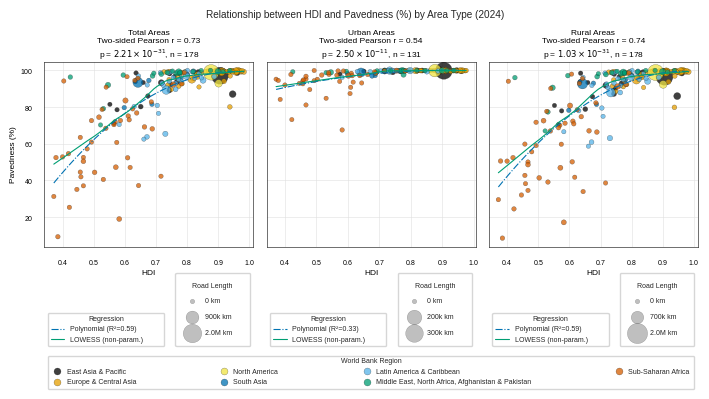

In [26]:
create_scatter_plots(gdf_countries, df_shdi, df_wb, year=2024,
                     regression_types=("lowess", "polynomial"), color_bubbles_mono=False,
                     color_axes=True)


### 4.5 create correlation plots for pavedness increas

In [27]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score
from scipy.stats import pearsonr
from statsmodels.nonparametric.smoothers_lowess import lowess
from matplotlib.lines import Line2D

import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
from matplotlib.colors import Normalize
from matplotlib.cm import get_cmap, ScalarMappable
import matplotlib.patheffects as PathEffects
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import pingouin as pg


INCREASE_MAP_CMAP = "plasma"  # CVD-friendly sequential, used over the fixed [0, 100] range


def make_2plus1_layout(figsize=(15, 6), wspace=0.22):
    fig = plt.figure(figsize=figsize)
    gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[2, 1], wspace=wspace)
    ax_map = fig.add_subplot(gs[0, 0], projection=ccrs.EqualEarth())
    ax_scat = fig.add_subplot(gs[0, 1])
    return fig, ax_map, ax_scat


def dissolve_world_for_bg(world_ll: "pd.DataFrame"):
    w = world_ll.copy()
    name_col = None
    for c in ("NAME", "ADMIN", "name", "Name", "CNTRY_NAME"):
        if c in w.columns:
            name_col = c
            break
    if name_col is not None:
        w = w[w[name_col] != "Antarctica"]
    if getattr(w, "crs", None) is None or w.crs.to_epsg() != 4326:
        w = w.to_crs(4326)
    return w.dissolve()  # single multipolygon row


def add_world_and_cartopy_gridlines(
    ax,
    world_gdf,
    world_dissolved_gdf,
    *,
    show_grid=True,
    boundary=True,
    boundary_color="dimgray",
    boundary_lw=0.4,
    boundary_alpha=0.9,
    fill_facecolor="lightgrey",
    fill_edgecolor="lightgrey",
    fill_lw=0.3,
):
    shadow_effect = [PathEffects.withSimplePatchShadow(
        offset=(1.5, -1.5), shadow_rgbFace='black', alpha=0.35
    )]

    if show_grid:
        gl = ax.gridlines(draw_labels=False, linewidth=0.3,
                          linestyle='--', color='gray', alpha=0.5, zorder=1)
        gl.xformatter = LONGITUDE_FORMATTER
        gl.yformatter = LATITUDE_FORMATTER
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": NRJ_FONT_SIZE_MIN_PT}
        gl.ylabel_style = {"size": NRJ_FONT_SIZE_MIN_PT}

    world_dissolved_gdf.plot(
        ax=ax, transform=ccrs.PlateCarree(),
        facecolor=fill_facecolor, edgecolor=fill_edgecolor,
        linewidth=fill_lw, path_effects=shadow_effect, zorder=2
    )

    if boundary:
        world_gdf.boundary.plot(
            ax=ax, transform=ccrs.PlateCarree(),
            color=boundary_color, linewidth=boundary_lw,
            alpha=boundary_alpha, zorder=2
        )

    ax.set_global()


def _safe_div(n, d):
    n = np.asarray(n, dtype=float)
    d = np.asarray(d, dtype=float)
    out = np.full_like(n, np.nan, dtype=float)
    mask = np.isfinite(n) & np.isfinite(d) & (np.abs(d) > 0)
    out[mask] = n[mask] / d[mask]
    return out


def _clip_prop(p, eps=1e-6):
    return np.clip(np.asarray(p, dtype=float), eps, 1 - eps)


def _sci_label(val: float, ndigits: int = 3) -> str:
    """
    Scientific label with a floating base, e.g. 2.67 × 10^6

    ndigits controls the total significant digits (approx) in the base.
    For ndigits=3 and 1 <= base < 10 -> 2 decimals.
    """
    if not np.isfinite(val) or val == 0:
        return "0"

    exp = int(np.floor(np.log10(abs(val))))
    base = val / (10 ** exp)

    # number of decimals so total sig-digits ~ ndigits when 1 <= base < 10
    decimals = max(ndigits - 1, 0)
    base_str = f"{base:.{decimals}f}".rstrip("0").rstrip(".")

    return rf"${base_str} \times 10^{{{exp}}}$"


def _snap_to_125(x: float) -> float:
    if x <= 0 or not np.isfinite(x):
        return 0.0
    exp = int(np.floor(np.log10(x)))
    candidates = np.array([1.0, 2.0, 5.0]) * (10 ** exp)
    idx = np.argmin(np.abs(candidates - x))
    return float(candidates[idx])


def _nice_legend_values(Lmax: float, k: int = 4, floor_frac: float = 0.08) -> list:
    if not np.isfinite(Lmax) or Lmax <= 0:
        return []
    seeds = np.linspace(floor_frac, 1.0, num=6)
    vals = []
    for f in seeds:
        v = _snap_to_125(Lmax * f)
        if v > 0:
            vals.append(v)
    vals = sorted(set(vals))
    lo = Lmax * floor_frac * 0.8
    hi = Lmax * 1.01
    vals = [v for v in vals if lo <= v <= hi]
    if not vals:
        vals = [Lmax]
    if len(vals) > k:
        idx = np.unique(np.linspace(0, len(vals) - 1, num=k).astype(int))
        vals = [vals[i] for i in idx]
    return vals


def _legend_values_with_zero(Lmax: float, n: int = 4) -> list:
    vals = [0.0]
    nonzero = _nice_legend_values(Lmax, k=max(n - 1, 1), floor_frac=0.08)
    vals.extend(nonzero)
    if len(vals) < n and np.isfinite(Lmax) and Lmax > 0:
        for f in [0.05, 0.1, 0.2]:
            v = _snap_to_125(Lmax * f)
            if v not in vals and v > 0:
                vals.append(v)
            if len(vals) >= n:
                break
    vals = sorted(set(vals))[:n]
    return vals


def _legend_values_fractional(
    Lmax: float,
    n: int = 4,
    bubble_size_min: float = 25.0,
    bubble_size_max: float = 1200.0,
) -> list:
    if not np.isfinite(Lmax) or Lmax <= 0:
        return [0.0] * n

    if n <= 1:
        return [0.0]
    if n == 2:
        return [0.0, float(Lmax)]

    s_min = float(bubble_size_min)
    s_max = float(bubble_size_max)
    S = s_max - s_min
    if S <= 0:
        fracs = np.linspace(0.0, 1.0, n)
        return (fracs * float(Lmax)).tolist()

    m = n - 1
    q_list = np.linspace(0.5, 1.0, m)

    vals = [0.0]
    for q in q_list:
        target_s = (q ** 2) * s_max
        L_i = Lmax * (target_s - s_min) / S
        L_i = max(0.0, min(float(Lmax), float(L_i)))
        vals.append(L_i)

    vals[0] = 0.0
    vals[-1] = float(Lmax)

    return vals


def _residualize(y_vec: np.ndarray, X_df: pd.DataFrame, method="pearson"):
    y = pd.Series(y_vec, name="y")
    df = pd.concat([y, X_df], axis=1).dropna()
    if df.empty:
        return np.array([]), df.index

    yv = df["y"].to_numpy().astype(float)
    X = df.drop(columns=["y"]).copy()

    if method == "spearman":
        yv = pd.Series(yv).rank(method="average").to_numpy()
        for c in X.columns:
            if np.issubdtype(X[c].dtype, np.number) and X[c].nunique() > 2:
                X[c] = X[c].rank(method="average")

    lr = LinearRegression().fit(X, yv)
    res = yv - lr.predict(X)
    return res, df.index


def _partial_corr_with_residuals(x, y, controls_df, method="pearson"):
    rx, ix = _residualize(x, controls_df, method=method)
    ry, iy = _residualize(y, controls_df, method=method)
    common = ix.intersection(iy)
    if len(common) < 3:
        return np.nan, np.nan, len(common), np.array([]), np.array([]), common

    rx = rx[np.isin(ix, common)]
    ry = ry[np.isin(iy, common)]
    mask = np.isfinite(rx) & np.isfinite(ry)
    if mask.sum() < 3:
        return np.nan, np.nan, mask.sum(), rx, ry, common

    r, p = pearsonr(rx[mask], ry[mask])
    rx = rx[mask]
    ry = ry[mask]
    idx_used = common[mask]
    return r, p, mask.sum(), rx, ry, idx_used


def _artist_height_in_figure_coords(fig, artist):
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    bbox = artist.get_window_extent(renderer=renderer)
    bbox_fig = bbox.transformed(fig.transFigure.inverted())
    return bbox_fig.height


def add_size_legend_inset(
    fig,
    anchor_ax,
    legend_vals,
    L_max,
    bubble_size_min,
    bubble_size_max,
    loc="lower left",
    pad=0.02,
    title="Total Road Length (2024)",
    unit="km",
    center_x=None,
    bottom=None,
    frame_style=None,
):
    legend_vals = np.asarray(legend_vals, dtype=float)
    if legend_vals.size == 0:
        return None

    if np.isfinite(L_max) and L_max > 0:
        L_ref = float(L_max)
    else:
        valid_L = legend_vals[np.isfinite(legend_vals)]
        if valid_L.size == 0:
            return None
        L_ref = float(valid_L.max())

    s_min = float(bubble_size_min)
    s_max = float(bubble_size_max)
    S = s_max - s_min
    if S <= 0:
        return None

    s_vals = np.full_like(legend_vals, np.nan, dtype=float)
    valid = np.isfinite(legend_vals)
    s_vals[valid] = s_min + S * (legend_vals[valid] / L_ref)
    s_vals = np.clip(s_vals, 0, None)

    s_max_eff = np.nanmax(s_vals)
    if not np.isfinite(s_max_eff) or s_max_eff <= 0:
        return None

    r_pts = np.sqrt(s_vals / np.pi)
    r_pt_max = np.nanmax(r_pts)
    if r_pt_max <= 0:
        return None

    fig_w_in, fig_h_in = fig.get_size_inches()
    diam_in = 2 * r_pt_max / 72.0
    margin_factor = 1.4
    axis_h_in = diam_in * margin_factor
    axis_w_in = axis_h_in

    w_frac = axis_w_in / fig_w_in
    h_frac = axis_h_in / fig_h_in

    bbox = anchor_ax.get_position()
    if loc == "lower left":
        left = bbox.x0 + pad * bbox.width
        bottom_final = bbox.y0 + pad * bbox.height
    elif loc == "lower right":
        left = bbox.x1 - pad * bbox.width - w_frac
        bottom_final = bbox.y0 + pad * bbox.height
    elif loc == "upper left":
        left = bbox.x0 + pad * bbox.width
        bottom_final = bbox.y1 - pad * bbox.height - h_frac
    elif loc == "upper right":
        left = bbox.x1 - pad * bbox.width - w_frac
        bottom_final = bbox.y1 - pad * bbox.height - h_frac
    elif loc == "below_center":
        if center_x is None:
            fig_children = fig.axes
            if len(fig_children) >= 2:
                ax0, ax1 = fig_children[0], fig_children[1]
                bbox0, bbox1 = ax0.get_position(), ax1.get_position()
                left_all = min(bbox0.x0, bbox1.x0)
                right_all = max(bbox0.x1, bbox1.x1)
                center_x = 0.5 * (left_all + right_all)
            else:
                center_x = bbox.x0 + bbox.width / 2.0

        if bottom is None:
            bottom = -0.5

        left = center_x - w_frac / 2.0
        bottom_final = bottom
    else:
        left = bbox.x0 + pad * bbox.width
        bottom_final = bbox.y0 + pad * bbox.height

    ax_leg = fig.add_axes([left, bottom_final, w_frac, h_frac])

    r_axes_max = 1.0 / (2.0 * margin_factor)
    r_rel = r_pts / r_pt_max
    r_axes = r_axes_max * r_rel

    left_margin = 0.02
    x_center = r_axes_max + left_margin
    right_edge = x_center + r_axes_max
    x_line_end = min(0.95, right_edge + 0.06)
    x_label = min(0.97, x_line_end + 0.02)
    baseline = 0.05

    for L_val, r_a in zip(legend_vals, r_axes):
        cy = baseline + r_a
        top_y = cy + r_a

        circ = plt.Circle(
            (x_center, cy),
            r_a,
            transform=ax_leg.transAxes,
            edgecolor="k",
            facecolor="none",
            linewidth=0.5,
            clip_on=False,
        )
        ax_leg.add_patch(circ)

        ax_leg.plot(
            [x_center, x_line_end],
            [top_y, top_y],
            color="k",
            linewidth=0.5,
            transform=ax_leg.transAxes,
            clip_on=False,
        )

        ax_leg.text(
            x_label,
            top_y,
            _sci_label(L_val / 1000) + f" {unit}",
            va="center",
            fontsize=NRJ_FONT_SIZE_MIN_PT,
            transform=ax_leg.transAxes,
            clip_on=False,
        )

    ax_leg.set_xlim(0, 1)
    ax_leg.set_ylim(0, 1)
    ax_leg.set_aspect("equal", adjustable="datalim")
    ax_leg.axis("off")

    # Title: left-aligned with the leftmost circle border (axes x = left_margin).
    ax_leg.set_title(title, fontsize=NRJ_FONT_SIZE_MIN_PT, pad=2, loc="left")
    ax_leg.title.set_x(left_margin)

    # Lift the inset above the map (and any other axes) so circles/labels are
    # never occluded.
    ax_leg.set_zorder(1000)

    if frame_style is not None:
        from matplotlib.patches import FancyBboxPatch
        pad_x = 0.006
        pad_y = 0.006

        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        tb = ax_leg.get_tightbbox(renderer)
        fb = tb.transformed(fig.transFigure.inverted())

        # Shift the inset vertically so the FRAME bottom (not the inset axes'
        # tight bbox bottom) aligns with `bottom_final`. This matches the
        # regression legend, whose frame bottom lies exactly at its anchor y.
        shift = bottom_final - (fb.y0 - pad_y)
        if abs(shift) > 1e-9:
            cur = ax_leg.get_position()
            ax_leg.set_position([cur.x0, cur.y0 + shift, cur.width, cur.height])
            fig.canvas.draw()
            tb = ax_leg.get_tightbbox(renderer)
            fb = tb.transformed(fig.transFigure.inverted())

        frame_patch = FancyBboxPatch(
            (fb.x0 - pad_x, fb.y0 - pad_y),
            fb.width + 2 * pad_x,
            fb.height + 2 * pad_y,
            boxstyle="round,pad=0,rounding_size=0.008",
            transform=fig.transFigure,
            edgecolor=frame_style["edgecolor"],
            facecolor=frame_style["facecolor"],
            alpha=frame_style["framealpha"],
            linewidth=frame_style["linewidth"],
            zorder=999,
            clip_on=False,
        )
        fig.add_artist(frame_patch)

    return ax_leg


def correlate_indicator_and_pavedness_increase(
    gdf_countries, gdf_indicators, merge_on, indicator, world, df_wb,
    bubble_size_min=15, bubble_size_max=350,
    regression_types=("linear", "log", "polynomial", "lowess"),
    corr_type="pearson",
    plot_measure="abs_pp",
    outpng="./plots/increase_pavedness_vs_indicator_equalearth.png",
    legend_n=4,
    debug_missing: bool = True,
    controlled_regression: bool = False,
    use_controls=False,
    filter_pavedness_2020=90,
    filter_unpaved_length_2020=100000,
    test_mode: bool = False,
):
    LEGEND_KW = dict(
        fontsize=NRJ_FONT_SIZE_MIN_PT,
        title_fontsize=NRJ_FONT_SIZE_MIN_PT,
        borderpad=0.6,
        labelspacing=0.5,
        handletextpad=0.5,
        frameon=True,
    )
    FRAME_STYLE = dict(
        edgecolor="#888888",
        facecolor="white",
        framealpha=1.0,
        linewidth=0.4,
    )

    import seaborn as sns
    sns.set_theme(style="whitegrid", rc={
        "axes.grid": True,
        "grid.linewidth": 0.4,
        "grid.color": "#e0e0e0",
    })
    plt.rcParams.update({
        "font.family": NRJ_FONT_FAMILY,
        "font.size": NRJ_FONT_SIZE_MAX_PT,
        "axes.titlesize": NRJ_FONT_SIZE_MAX_PT,
        "axes.labelsize": NRJ_FONT_SIZE_MAX_PT,
        "xtick.labelsize": NRJ_FONT_SIZE_MIN_PT,
        "ytick.labelsize": NRJ_FONT_SIZE_MIN_PT,
        "legend.fontsize": NRJ_FONT_SIZE_MIN_PT,
        "legend.title_fontsize": NRJ_FONT_SIZE_MIN_PT,
        "lines.linewidth": 0.8,
        "axes.linewidth": 0.4,
        "axes.edgecolor": "#888888",
        "axes.formatter.use_mathtext": True,
        "xtick.major.pad": 2,
        "ytick.major.pad": 2,
        "axes.labelpad": 2,
    })

    indicator_display = "HDI" if indicator.lower() == "shdi" else indicator.upper()

    def _compute_pavedness(df, year):
        g = df[df[f"road_class_{year}"].isin(["paved", "unpaved"])].copy()
        g = g.groupby(['iso_A3', 'urban_rural', f"road_class_{year}"])[f"length_{year}"].sum().reset_index()
        paved = g[g[f"road_class_{year}"] == "paved"].rename(columns={f"length_{year}": "length_paved"})
        unpaved = g[g[f"road_class_{year}"] == "unpaved"].rename(columns={f"length_{year}": "length_unpaved"})
        out = paved.merge(unpaved, on=['iso_A3', 'urban_rural'], how='outer')
        out['pavedness'] = 100 * out['length_paved'] / (out['length_paved'] + out['length_unpaved'])
        out["combined_length"] = out["length_paved"] + out["length_unpaved"]
        return out

    g2020 = _compute_pavedness(gdf_countries, 2020)
    g2024 = _compute_pavedness(gdf_countries, 2024)

    g = g2024.merge(g2020, on=["iso_A3", "urban_rural"], suffixes=("_2024", "_2020"))
    g = g[g["urban_rural"] == "total"].copy()

    p20 = g["pavedness_2020"] / 100.0
    p24 = g["pavedness_2024"] / 100.0
    p20c = _clip_prop(p20.values)
    p24c = _clip_prop(p24.values)

    L20 = g["combined_length_2020"].values
    L24 = g["combined_length_2024"].values

    paved20 = p20.values * L20
    paved24 = p24.values * L24

    g["abs_pp"] = g["pavedness_2024"] - g["pavedness_2020"]
    g["rel_pct"] = _safe_div(g["abs_pp"], g["pavedness_2020"]) * 100.0
    g["ratio"] = _safe_div(p24, p20)
    g["log_ratio"] = np.log(_safe_div(p24c, p20c))
    g["logit_diff"] = np.log(_safe_div(p24c, 1 - p24c)) - np.log(_safe_div(p20c, 1 - p20c))
    g["cohens_h"] = 2 * (np.arcsin(np.sqrt(p24c)) - np.arcsin(np.sqrt(p20c)))
    g["paved_km_change_norm"] = _safe_div(paved24 - paved20, L24 - L20)
    g["by_potential"] = _safe_div(p24 - p20, 1.0 - p20) * 100.0
    g["ndi"] = _safe_div(p24 - p20, p24 + p20)

    g["length_weight"] = g["combined_length_2024"]

    g = g.merge(gdf_indicators, left_on="iso_A3", right_on=merge_on, how="left")
    g = g.merge(df_wb[["iso_alpha3", "wb_region"]], left_on="iso_A3", right_on="iso_alpha3", how="left")
    g[indicator] = pd.to_numeric(g[indicator], errors="coerce")
    g["filter"] = (
        (g["length_unpaved_2020"] > filter_unpaved_length_2020)
        & (g["pavedness_2020"] < filter_pavedness_2020)
    )

    label_map = {
        "abs_pp": "Increase in Pavedness (pp)",
        "rel_pct": "Relative Change (%)",
        "ratio": "Pavedness Ratio (p24/p20)",
        "log_ratio": "Log Ratio ln(p24/p20)",
        "logit_diff": "Logit Difference Δlogit(p)",
        "cohens_h": "Cohen's h",
        "paved_km_change_norm": "Δ Paved km / Δ Total km",
        "by_potential": "Change in Pavedness (2020→2024) \n normalized by potential (%)",
        "ndi": "Normalized Difference Index (NDI)",
    }
    if plot_measure not in label_map:
        raise ValueError(f"Unknown plot_measure '{plot_measure}'")
    measure_label = label_map[plot_measure]

    fig, ax_map, ax_scat = make_2plus1_layout(
        figsize=(NRJ_2COL_WIDTH_IN, NRJ_2COL_WIDTH_IN * 0.40), wspace=0.22
    )

    world_ll = world.to_crs(4326)
    world_key = "ADM0_A3" if "ADM0_A3" in world_ll.columns else "iso_A3"
    world_for_pts = world_ll[[world_key, "geometry"]].copy()

    if not test_mode:
        world_dissolved = dissolve_world_for_bg(world_ll)
        add_world_and_cartopy_gridlines(ax_map, world_ll, world_dissolved)
    else:
        ax_map.set_global()

    gm = world_for_pts.merge(
        g[["iso_A3", plot_measure, "length_weight", "filter"]],
        left_on=world_key, right_on="iso_A3", how="left"
    ).dropna(subset=[plot_measure, "length_weight"]).copy()

    gm["rep_pt"] = gm.geometry.representative_point()
    gm["lon"] = gm["rep_pt"].x
    gm["lat"] = gm["rep_pt"].y

    L = gm["length_weight"].to_numpy().astype(float)
    L_max = np.nanmax(L)
    if L_max <= 0 or not np.isfinite(L_max):
        raise ValueError("Non-positive or invalid maximum length_weight; cannot scale bubbles.")
    gm["bubble_size"] = (L / L_max) * (bubble_size_max - bubble_size_min) + bubble_size_min

    map_vals = _legend_values_fractional(
        L_max,
        n=legend_n,
        bubble_size_min=bubble_size_min,
        bubble_size_max=bubble_size_max,
    )

    vmin, vmax = 0.0, 100.0
    cmap_obj = get_cmap(INCREASE_MAP_CMAP)
    norm = Normalize(vmin=vmin, vmax=vmax)

    gm["filter"] = gm["filter"].fillna(False).astype(bool)
    gm_used = gm[gm["filter"]]
    gm_unused = gm[~gm["filter"]]

    vals_used = gm_used[plot_measure].to_numpy().astype(float)
    ax_map.scatter(
        gm_used["lon"], gm_used["lat"],
        s=gm_used["bubble_size"],
        c=vals_used, cmap=cmap_obj, norm=norm,
        transform=ccrs.PlateCarree(),
        edgecolors="k", linewidths=0.3, alpha=0.9, zorder=3
    )

    vals_unused = gm_unused[plot_measure].to_numpy().astype(float)
    ax_map.scatter(
        gm_unused["lon"], gm_unused["lat"],
        s=gm_unused["bubble_size"],
        c=vals_unused, cmap=cmap_obj, norm=norm,
        transform=ccrs.PlateCarree(),
        edgecolors="k", linewidths=0.3, alpha=0.3, zorder=3
    )

    sm = ScalarMappable(norm=norm, cmap=cmap_obj)
    sm.set_array([])
    cb = plt.colorbar(sm, ax=ax_map, orientation='horizontal', pad=0.02, fraction=0.05)
    cb.set_label(measure_label)
    cb.ax.tick_params(width=0.4, length=2, pad=0.5)
    cb.outline.set_linewidth(0.4)

    ax_map.set_title(measure_label, fontsize=NRJ_FONT_SIZE_MAX_PT)

    corr_df = g.dropna(subset=[plot_measure, indicator, "length_weight", "wb_region"]).copy()
    if corr_df.empty:
        print("No data available for scatter plot.")
        plt.tight_layout()
        dirpath = os.path.dirname(outpng)
        if dirpath:
            os.makedirs(dirpath, exist_ok=True)
        plt.savefig(outpng, dpi=NRJ_DPI, bbox_inches="tight")
        plt.show()
        return outpng, corr_df, corr_df, pd.DataFrame()

    wb_regions = _ordered_wb_regions(corr_df['wb_region'].dropna().unique())
    region_color = _wb_region_color_map(wb_regions)
    _log_wb_region_colors(region_color)

    controls = pd.DataFrame(index=corr_df.index)
    controls["p20"] = p20.reindex(corr_df.index).values
    if plot_measure == "paved_km_change_norm":
        controls["dL"] = (
            pd.Series(L24, index=g.index).reindex(corr_df.index).values
            - pd.Series(L20, index=g.index).reindex(corr_df.index).values
        )

    if debug_missing:
        debug_df = pd.concat(
            [corr_df[[indicator, plot_measure, "length_weight", "wb_region"]], controls],
            axis=1
        )
        print("=== Missing values before partial correlation (corr_df + controls) ===")
        na_counts = debug_df.isna().sum().sort_values(ascending=False)
        print(na_counts)
        na_nonzero = na_counts[na_counts > 0]
        if not na_nonzero.empty and not test_mode:
            plt.figure(figsize=(6, 3))
            na_nonzero.plot(kind="bar")
            plt.title("Missing values per column (corr_df + controls)")
            plt.ylabel("# missing")
            plt.tight_layout()
            plt.show()

    if use_controls:
        pc_df = pd.concat(
            [corr_df[[indicator, plot_measure]], controls],
            axis=1
        ).dropna()
        covars = list(controls.columns)
    else:
        pc_df = corr_df[[indicator, plot_measure, "pavedness_2020", "length_unpaved_2020"]].dropna()
        pc_df = pc_df[pc_df["pavedness_2020"] <= filter_pavedness_2020]
        pc_df = pc_df[pc_df["length_unpaved_2020"] >= filter_unpaved_length_2020]
        pc_df = pc_df[[indicator, plot_measure, "pavedness_2020"]]
        covars = ["pavedness_2020"]

    if pc_df.shape[0] >= 3:
        res_pg = pg.partial_corr(
            data=pc_df,
            x=indicator,
            y=plot_measure,
            covar=covars,
            method=corr_type
        ).iloc[0]
        r_part = float(res_pg["r"])
        p_part = float(res_pg["p-val"])
        n_used = int(res_pg["n"])
        ci_part = np.asarray(res_pg["CI95%"], dtype=float)
        idx_used_pc = pc_df.index
    else:
        r_part = np.nan
        p_part = np.nan
        n_used = pc_df.shape[0]
        ci_part = np.array([np.nan, np.nan])
        idx_used_pc = pc_df.index

    df_used = corr_df.loc[idx_used_pc].copy()
    corr_df["used_in_pc"] = corr_df.index.isin(idx_used_pc)

    corr_df["bubble_size"] = (
        corr_df["length_weight"] / corr_df["length_weight"].max()
        * (bubble_size_max - bubble_size_min) + bubble_size_min
    )

    for region in wb_regions:
        rdat = corr_df[corr_df["wb_region"] == region]

        rdat_out = rdat[~rdat["used_in_pc"]]
        rdat_in = rdat[rdat["used_in_pc"]]

        if not rdat_out.empty:
            ax_scat.scatter(
                rdat_out[indicator], rdat_out[plot_measure],
                s=rdat_out["bubble_size"],
                **_wb_region_scatter_kwargs(region, region_color, alpha=0.20),
                label=None,
            )

        if not rdat_in.empty:
            ax_scat.scatter(
                rdat_in[indicator], rdat_in[plot_measure],
                s=rdat_in["bubble_size"],
                **_wb_region_scatter_kwargs(region, region_color, alpha=0.85, linewidths=0.4),
                label=region,
            )

    reg_handles = []
    handles_wb = []

    if not test_mode:
        x_raw = corr_df[indicator].to_numpy()
        y_raw = corr_df[plot_measure].to_numpy()
        mask_raw = np.isfinite(x_raw) & np.isfinite(y_raw)

        if "linear" in regression_types and mask_raw.sum() > 2:
            x_lin = x_raw[mask_raw].reshape(-1, 1)
            y_lin_data = y_raw[mask_raw]
            mdl_lin = LinearRegression().fit(x_lin, y_lin_data)
            xp = np.linspace(x_lin.min(), x_lin.max(), 200).reshape(-1, 1)
            yp = mdl_lin.predict(xp)
            r2_lin = r2_score(y_lin_data, mdl_lin.predict(x_lin))
            ax_scat.plot(xp.ravel(), yp, linestyle="--", color="gray")
            reg_handles.append(
                Line2D([0], [0], linestyle="--", color="gray", label=f"Linear (raw, R²={r2_lin:.2f})")
            )

        if "polynomial" in regression_types and mask_raw.sum() > 2:
            x_fr = x_raw[mask_raw].reshape(-1, 1)
            y_fr = y_raw[mask_raw]
            poly = PolynomialFeatures(2, include_bias=True)
            Xp = poly.fit_transform(x_fr)
            mdl_poly = LinearRegression().fit(Xp, y_fr)
            xp = np.linspace(x_fr.min(), x_fr.max(), 200).reshape(-1, 1)
            yp = mdl_poly.predict(poly.transform(xp))
            r2_poly = r2_score(y_fr, mdl_poly.predict(Xp))
            ax_scat.plot(xp.ravel(), yp, linestyle="-.", color="#0072B2")
            reg_handles.append(
                Line2D([0], [0], linestyle="-.", color="#0072B2", label=f"Poly (raw, R²={r2_poly:.2f})")
            )

        if "lowess" in regression_types and mask_raw.sum() > 1:
            lw = lowess(y_raw[mask_raw], x_raw[mask_raw], frac=0.3)
            ax_scat.plot(lw[:, 0], lw[:, 1], color="#009E73")
            reg_handles.append(
                Line2D([0], [0], linestyle="-", color="#009E73", label="LOWESS (raw)")
            )

        if np.isfinite(p_part):
            if p_part < 1e-3:
                stars = "***"; p_text = f"p = {_sci_label(p_part)}"
            elif p_part < 1e-2:
                stars = "**"; p_text = f"p = {p_part:.3g}"
            elif p_part < 5e-2:
                stars = "*"; p_text = f"p = {p_part:.3g}"
            else:
                stars = "ns"; p_text = f"p = {p_part:.3g}"
        else:
            stars = "n/a"
            p_text = "p = n/a"

        title_stats = (
            f"Two-sided partial {corr_type}\n r = {r_part:.2f} \n "
            f"{p_text}, n = {n_used} \n"
            "correct for pavedness in 2020"
        )

        handles_wb = [
            _wb_region_legend_handle(r, region_color, alpha=0.85, markeredgewidth=0.4)
            for r in wb_regions
        ]

    _title_line2 = title_stats if (not test_mode and 'title_stats' in dir()) else ""
    ax_scat.set_title(_title_line2, fontsize=NRJ_FONT_SIZE_MAX_PT, pad=3)
    ax_scat.set_xlabel(indicator_display, fontsize=NRJ_FONT_SIZE_MAX_PT, labelpad=1)
    ax_scat.set_ylabel(measure_label, fontsize=NRJ_FONT_SIZE_MAX_PT, labelpad=1)
    ax_scat.tick_params(axis="both", which="major", pad=0.5, length=1.5, width=0.4)
    ax_scat.tick_params(axis="both", which="minor", pad=0.5, length=1.0, width=0.4)
    ax_scat.margins(x=0.05)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.25)
    fig.canvas.draw()

    # Use subplot frame, not full figure, so all legend frames align with axes block
    axes_left = fig.subplotpars.left
    axes_right = fig.subplotpars.right
    axes_width = axes_right - axes_left
    scat_pos = ax_scat.get_position()
    scat_left = scat_pos.x0
    scat_width = scat_pos.width

    legend_gap = 0.012
    base_y = -0.125
    current_top = base_y
    reg_y = None

    # World Bank legend
    if not test_mode and handles_wb:
        wb_leg = fig.legend(
            handles=handles_wb,
            title='World Bank Region',
            bbox_to_anchor=(axes_left, base_y, axes_width, 0.0),
            bbox_transform=fig.transFigure,
            loc='lower left',
            mode='expand',
            ncol=4,
            **LEGEND_KW,
        )
        fr = wb_leg.get_frame()
        fr.set_edgecolor(FRAME_STYLE['edgecolor'])
        fr.set_facecolor(FRAME_STYLE['facecolor'])
        fr.set_alpha(FRAME_STYLE['framealpha'])
        fr.set_linewidth(FRAME_STYLE['linewidth'])

        wb_h = _artist_height_in_figure_coords(fig, wb_leg)
        current_top = base_y + wb_h

    # Regression legend
    if not test_mode and reg_handles:
        reg_y = current_top + legend_gap

        reg_leg = fig.legend(
            handles=reg_handles,
            title='Regression',
            bbox_to_anchor=(scat_left, reg_y, scat_width, 0.0),
            bbox_transform=fig.transFigure,
            loc='lower left',
            mode='expand',
            ncol=1,
            **LEGEND_KW,
        )
        fr = reg_leg.get_frame()
        fr.set_edgecolor(FRAME_STYLE['edgecolor'])
        fr.set_facecolor(FRAME_STYLE['facecolor'])
        fr.set_alpha(FRAME_STYLE['framealpha'])
        fr.set_linewidth(FRAME_STYLE['linewidth'])

    # Size legend inset, bottom-aligned with the regression legend, centered under the map column
    if not test_mode:
        map_pos = ax_map.get_position()
        size_center_x = map_pos.x0 + 0.96 * (map_pos.x1 - map_pos.x0)
        size_bottom = reg_y + 0.01 if reg_y is not None else current_top + legend_gap

        add_size_legend_inset(
            fig=fig,
            anchor_ax=ax_map,
            legend_vals=map_vals,
            L_max=L_max,
            bubble_size_min=bubble_size_min,
            bubble_size_max=bubble_size_max,
            loc="below_center",
            center_x=size_center_x,
            bottom=size_bottom,
            pad=0.02,
            title="Total Road Length (2024)",
            unit="km",
            frame_style=FRAME_STYLE,
        )

    dirpath = os.path.dirname(outpng)
    if dirpath:
        os.makedirs(dirpath, exist_ok=True)
    plt.savefig(outpng, dpi=NRJ_DPI, bbox_inches="tight")
    plt.show()

    return outpng, df_used, corr_df, controls

WB region palette used: wong_standard
  East Asia & Pacific: #000000
  Europe & Central Asia: #E69F00
  North America: #F0E442
  South Asia: #0072B2
  Latin America & Caribbean : #56B4E9
  Middle East, North Africa, Afghanistan & Pakistan: #009E73
  Sub-Saharan Africa : #D55E00


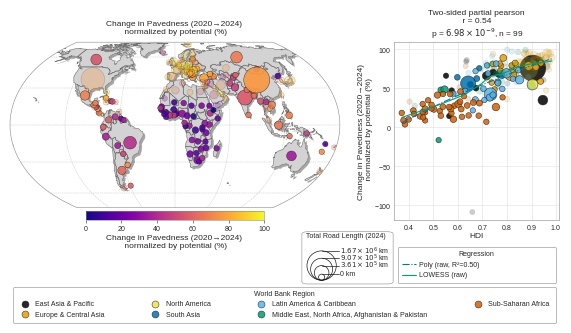

In [28]:
png, df_used, corr_df, controls  = correlate_indicator_and_pavedness_increase(
    gdf_countries=gdf_countries,
    gdf_indicators=df_shdi,
    merge_on="iso_code",
    indicator="shdi",
    world=world,
    df_wb=df_wb,
    regression_types=("lowess","polynomial"),
    corr_type="pearson",
    plot_measure="by_potential",
    outpng="./plots/increase_pavedness_shdi_equalearth.png",
    debug_missing=False,
    filter_pavedness_2020=90,
    filter_unpaved_length_2020=100*1000,
    test_mode=False,
)